# Verify U-Net validation performance against the held-out test set

Evaluate one **frozen checkpoint** on the original starter validation (60 recordings) and test (40 recordings) splits. The default is the best validation model from the saved six-trial grid: U-Net/8, BCE, learning rate 0.001, epoch 33. This is the original grid model, not a duty-cycle B model. Change `RUN_DIR` to evaluate another grid checkpoint.

No retraining or test-based tuning occurs. Normalization comes from the checkpoint (fit on clean training recordings); the decision threshold comes from its saved clean-validation calibration and is unchanged on test. Antennas stay within their recording's split.

**Outputs:** pooled pixel AP, precision, recall, F1, FPR, positive-pixel prevalence, per-family metrics, PR curves, and test-minus-validation differences. AP uses the original 65,536-bin quantization, not an average of per-recording APs. Empty-label families have undefined AP/recall. Validation helped select this checkpoint, so it is not an independent estimate. Split composition and RFI prevalence can affect the gap; a higher test AP alone does not establish a better model.

Run all cells in `cs156b_env`. Full inference processes 1,000 antenna images; a GPU is recommended. Results are saved in a fresh subdirectory and existing training artifacts are untouched.

In [1]:
import os
import sys
import json
import hashlib
from datetime import datetime, timezone
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.metrics import precision_recall_curve, average_precision_score
from IPython.display import display

PROJECT_ROOT = Path(os.environ.get("RFI_PROJECT_ROOT",
    "/resnick/groups/CS156b/from_central/2026/njack2/rfi-removal")).resolve()
RUN_DIR = Path(os.environ.get("RFI_VERIFY_RUN_DIR", str(PROJECT_ROOT /
    "results/runs/grid_20261022T083531Z_pmuteget_unet_b8_0b2beafa/bce_lr0.001"))).resolve()
DATA = PROJECT_ROOT / "data/starter-v1.0"
OUTPUT_DIR = PROJECT_ROOT / "results/validation_vs_test" / (
    RUN_DIR.parent.name + "_" + RUN_DIR.name + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ"))
for path in [PROJECT_ROOT / "src", PROJECT_ROOT / "vendor/dsa110/src"]:
    sys.path.insert(0, str(path))
from cs163_rfi import load_recording

torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
print("Frozen run:", RUN_DIR)

def sha256_file(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

Device: cpu
Frozen run: /resnick/groups/CS156b/from_central/2026/njack2/rfi-removal/results/runs/grid_20261022T083531Z_pmuteget_unet_b8_0b2beafa/bce_lr0.001


## Load and verify the model and split metadata

In [2]:
class DoubleConv(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, 3, padding=1), nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, 3, padding=1), nn.ReLU(inplace=True))
    def forward(self, x): return self.layers(x)

class SegmentationModel(nn.Module):
    """Two-level U-Net; use_skips=False gives the matched no-skip CNN."""
    def __init__(self, base=8, use_skips=True):
        super().__init__()
        self.use_skips = use_skips
        self.enc1 = DoubleConv(1, base)
        self.enc2 = DoubleConv(base, 2*base)
        self.pool = nn.MaxPool2d(2)
        self.bottleneck = DoubleConv(2*base, 4*base)
        self.up2 = nn.ConvTranspose2d(4*base, 2*base, 2, stride=2)
        self.dec2 = DoubleConv(4*base if use_skips else 2*base, 2*base)
        self.up1 = nn.ConvTranspose2d(2*base, base, 2, stride=2)
        self.dec1 = DoubleConv(2*base if use_skips else base, base)
        self.output = nn.Conv2d(base, 1, 1)
    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        z = self.bottleneck(self.pool(e2))
        z = self.up2(z)
        z = self.dec2(torch.cat((z, e2), dim=1) if self.use_skips else z)
        z = self.up1(z)
        z = self.dec1(torch.cat((z, e1), dim=1) if self.use_skips else z)
        return self.output(z)


In [3]:
config = json.loads((RUN_DIR / "config.json").read_text())
calibration = json.loads((RUN_DIR / "calibration.json").read_text())
status = json.loads((RUN_DIR / "training_status.json").read_text())
assert config["architecture"] == "unet"
assert status["status"] == "validation_plateau", "Use a completed training run."
checkpoint_sha = sha256_file(RUN_DIR / "best.pt")
assert checkpoint_sha == calibration["best_checkpoint_sha256"], "Threshold belongs to another checkpoint."
assert calibration["calibration_split"] == "validation"
# Only load trusted local project checkpoints.
checkpoint = torch.load(RUN_DIR / "best.pt", map_location="cpu", weights_only=False)
assert checkpoint["config"] == config
normalization = checkpoint["normalization"]
assert normalization["std"] > 0
bins = config["probability_bins"]
cut = calibration["quantized_cut"]
assert bins == calibration["probability_bins"] and 0 <= cut <= bins
model = SegmentationModel(config["base_channels"], use_skips=True).to(device)
model.load_state_dict(checkpoint["model_state_dict"], strict=True)
model.eval()

catalog = pd.read_csv(DATA / "dataset.csv")
assert catalog.sample_id.is_unique and catalog.path.is_unique
assert catalog.groupby("split").size().to_dict() == {"train": 100, "validation": 60, "test": 40}
assert sha256_file(DATA / "dataset.csv") == config["catalog_sha256"], "Catalog differs from training."
resolved_paths = [(DATA / p).resolve() for p in catalog.path]
assert len(set(resolved_paths)) == len(catalog)
assert all(p.is_relative_to(DATA.resolve()) for p in resolved_paths)
print("Checkpoint epoch:", checkpoint["epoch"])
print("Normalization:", normalization)
print("Frozen probability threshold:", cut / (bins - 1))
display(pd.crosstab(catalog.rfi_type, catalog.split))

Checkpoint epoch: 33
Normalization: {'mean': 4.257218322753906, 'std': 4.2564571117143295}
Frozen probability threshold: 0.10609597924773022


split,test,train,validation
rfi_type,,,
ask,2,5,3
bpsk,4,10,6
carrier,4,10,6
clean,2,5,3
digital,2,5,3
fsk,4,10,6
impulse,4,10,6
mixed,4,10,6
qpsk,2,5,3


## Evaluate both splits using the identical metric implementation

In [4]:
def quantize_probability(probability, bins):
    p = np.asarray(probability)
    assert bins >= 2 and np.isfinite(p).all() and ((p >= 0) & (p <= 1)).all()
    # Integer scores make histogram calibration, PR and hard masks agree exactly.
    return np.floor(p.astype(np.float64) * (bins - 1)).astype(np.int64)

def probability_histograms(probability, truth, bins):
    assert truth.dtype == np.bool_ and truth.shape == probability.shape
    q = quantize_probability(probability, bins)
    return (np.bincount(q[truth], minlength=bins), np.bincount(q[~truth], minlength=bins))

def precision_recall_from_histograms(positive, negative):
    """Let scikit-learn compute PR/AP; histogram counts are sample weights."""
    positive, negative = np.asarray(positive), np.asarray(negative)
    assert positive.shape == negative.shape and (positive >= 0).all() and (negative >= 0).all()
    if positive.sum() == 0:
        # Recall/AP are undefined when this family contains no positive labels.
        return {"precision": np.array([1.0]), "recall": np.array([np.nan]), "ap": np.nan}
    bins = len(positive)
    labels = np.r_[np.ones(bins), np.zeros(bins)]
    scores = np.tile(np.arange(bins), 2)
    weights = np.r_[positive, negative]
    present = weights > 0  # At most 2*bins observations; never expand millions of cells.
    labels, scores, weights = labels[present], scores[present], weights[present]
    precision, recall, _ = precision_recall_curve(labels, scores, sample_weight=weights)
    ap = average_precision_score(labels, scores, sample_weight=weights)
    return {"precision": precision[::-1], "recall": recall[::-1], "ap": float(ap)}


In [5]:
def metrics_from_histograms(positive, negative):
    tp, fp = int(positive[cut:].sum()), int(negative[cut:].sum())
    fn, tn = int(positive[:cut].sum()), int(negative[:cut].sum())
    def ratio(a, b): return a / b if b else np.nan
    return dict(pixel_ap=precision_recall_from_histograms(positive, negative)["ap"],
                precision=ratio(tp, tp + fp), recall=ratio(tp, tp + fn),
                f1=ratio(2 * tp, 2 * tp + fp + fn),
                false_positive_rate=ratio(fp, fp + tn),
                positive_fraction=ratio(tp + fn, tp + fp + fn + tn),
                tp=tp, fp=fp, fn=fn, tn=tn)

@torch.inference_mode()
def evaluate_frame(frame, split):
    overall = np.zeros((2, bins), dtype=np.int64)
    families, recording_rows = {}, []
    for number, row in enumerate(frame.itertuples(index=False), 1):
        recording = load_recording(DATA / row.path)
        power, truth = recording["power"], recording["rfi_mask"]
        assert power.shape == truth.shape == (4096, 10, 128, 1)
        assert np.isclose(truth.mean(), row.labelled_fraction, rtol=1e-5, atol=1e-8)
        hist = np.zeros_like(overall)
        for antenna in range(power.shape[1]):
            x = (power[:, antenna, :, 0].astype(np.float32) - normalization["mean"]) / normalization["std"]
            probability = model(torch.from_numpy(x)[None, None].to(device)).sigmoid()[0, 0].cpu().numpy()
            positive, negative = probability_histograms(
                probability, truth[:, antenna, :, 0].astype(bool), bins)
            hist[0] += positive
            hist[1] += negative
        overall += hist
        families.setdefault(row.rfi_type, np.zeros_like(overall))[:] += hist
        recording_rows.append(dict(split=split, sample_id=row.sample_id,
                                   rfi_type=row.rfi_type, **metrics_from_histograms(*hist)))
        if number % 10 == 0 or number == len(frame):
            print(f"{split}: {number}/{len(frame)} recordings", flush=True)
    assert overall.sum() == len(frame) * 4096 * 10 * 128
    return overall, families, recording_rows

# Small deterministic check of the histogram AP implementation.
p = np.array([0.1, 0.4, 0.4, 0.9], dtype=np.float32)
y = np.array([False, True, False, True])
ph, nh = probability_histograms(p, y, bins)
np.testing.assert_allclose(precision_recall_from_histograms(ph, nh)["ap"],
                           average_precision_score(y, quantize_probability(p, bins)))

histograms, family_histograms, recording_rows = {}, {}, []
for split in ["validation", "test"]:
    histograms[split], family_histograms[split], rows = evaluate_frame(
        catalog.loc[catalog.split.eq(split)], split)
    recording_rows.extend(rows)
assert histograms["validation"][0].sum() == 5799220
summary = pd.DataFrame([
    dict(split=split, recordings=int(catalog.split.eq(split).sum()),
         **metrics_from_histograms(*hist)) for split, hist in histograms.items()
]).set_index("split")
family_metrics = pd.DataFrame([
    dict(split=split, family=family, **metrics_from_histograms(*hist))
    for split, families in family_histograms.items() for family, hist in families.items()
])
display(summary)
display(family_metrics.pivot(index="family", columns="split", values="pixel_ap"))
comparison_metrics = ["pixel_ap", "precision", "recall", "f1", "false_positive_rate", "positive_fraction"]
display((summary.loc["test", comparison_metrics] - summary.loc["validation", comparison_metrics])
        .rename("test_minus_validation").to_frame())

validation: 10/60 recordings
validation: 20/60 recordings
validation: 30/60 recordings
validation: 40/60 recordings
validation: 50/60 recordings
validation: 60/60 recordings
test: 10/40 recordings
test: 20/40 recordings
test: 30/40 recordings
test: 40/40 recordings


,recordings,pixel_ap,precision,recall,f1,false_positive_rate,positive_fraction,tp,fp,fn,tn
split,,,,,,,,,,,
validation,60,0.634607,0.394998,0.683342,0.500619,0.019658,0.018435,3962848,6069734,1836372,302703846
test,40,0.744685,0.513970,0.739076,0.606303,0.019972,0.027782,4306149,4072058,1520244,199816749


split,test,validation
family,,
ask,0.068111,0.504164
bpsk,0.368314,0.042683
carrier,0.662395,0.764844
clean,NaN,NaN
digital,0.921843,0.937398
fsk,0.008029,0.030998
impulse,0.580489,0.770894
mixed,0.774423,0.650331
qpsk,0.002065,0.149355


,test_minus_validation
pixel_ap,0.110077
precision,0.118972
recall,0.055735
f1,0.105685
false_positive_rate,0.000314
positive_fraction,0.009347


## Verify validation reproduction and plot the comparison

Saved validation AP: 0.63460296
Recomputed validation AP: 0.63460735
Difference: +0.00000439


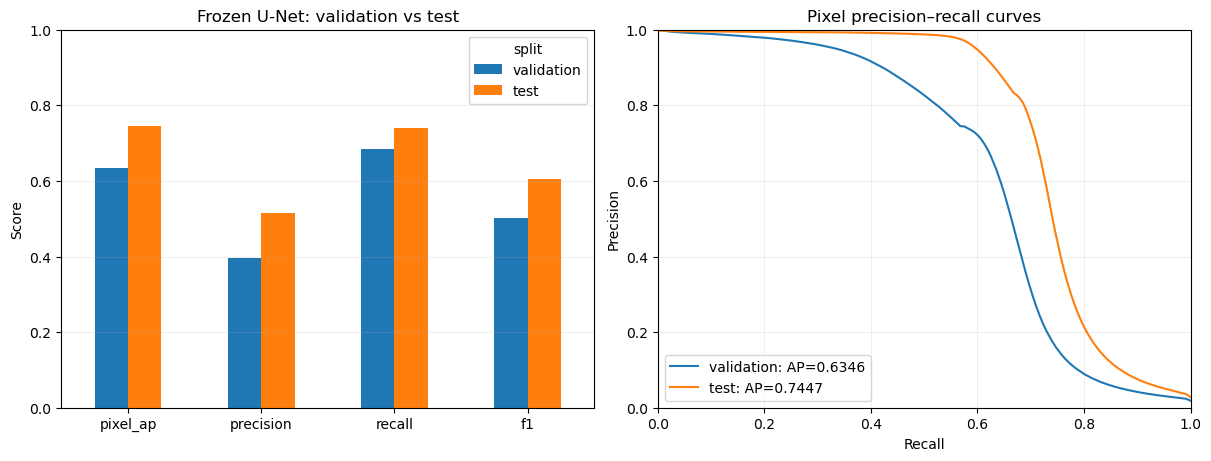

Saved comparison: /resnick/groups/CS156b/from_central/2026/njack2/rfi-removal/results/validation_vs_test/grid_20261022T083531Z_pmuteget_unet_b8_0b2beafa_bce_lr0.001_20261029T045046811227Z


In [6]:
# Compare against the original saved validation evaluation for this checkpoint.
references = []
for path in sorted(RUN_DIR.glob("evaluation_validation_*/summary.json")):
    saved = json.loads(path.read_text())
    if saved.get("calibration", {}).get("best_checkpoint_sha256") == checkpoint_sha:
        references.append((path, saved["pixel_ap_quantized"]))
if references:
    reference_path, reference_ap = references[-1]
    delta = summary.loc["validation", "pixel_ap"] - reference_ap
    print(f"Saved validation AP: {reference_ap:.8f}")
    print(f"Recomputed validation AP: {summary.loc['validation', 'pixel_ap']:.8f}")
    print(f"Difference: {delta:+.8f}")
    # Small CPU/GPU numerical differences are possible.
    if abs(delta) > 1e-4:
        raise ValueError("Validation AP failed to reproduce within 1e-4; investigate before interpreting test results.")
else:
    print("No matching saved validation summary found; only the fresh comparison is available.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout="constrained")
summary.loc[["validation", "test"], ["pixel_ap", "precision", "recall", "f1"]].T.plot.bar(
    ax=axes[0], color=["tab:blue", "tab:orange"], rot=0)
axes[0].set(title="Frozen U-Net: validation vs test", ylabel="Score", ylim=(0, 1))
axes[0].grid(axis="y", alpha=0.2)
for split, hist in histograms.items():
    curve = precision_recall_from_histograms(*hist)
    axes[1].plot(curve["recall"], curve["precision"],
                 label=f"{split}: AP={curve['ap']:.4f}")
axes[1].set(title="Pixel precision–recall curves", xlabel="Recall", ylabel="Precision",
            xlim=(0, 1), ylim=(0, 1))
axes[1].legend()
axes[1].grid(alpha=0.2)
plt.show()

OUTPUT_DIR.mkdir(parents=True, exist_ok=False)
summary.to_csv(OUTPUT_DIR / "overall_metrics.csv")
family_metrics.to_csv(OUTPUT_DIR / "per_family_metrics.csv", index=False)
pd.DataFrame(recording_rows).to_csv(OUTPUT_DIR / "per_recording_metrics.csv", index=False)
for split, hist in histograms.items():
    np.savez_compressed(OUTPUT_DIR / f"{split}_histograms.npz", positive=hist[0], negative=hist[1])
    curve = precision_recall_from_histograms(*hist)
    pd.DataFrame({"recall": curve["recall"], "precision": curve["precision"]}).to_csv(
        OUTPUT_DIR / f"{split}_pr_curve.csv", index=False)
for extension in ["png", "pdf"]:
    fig.savefig(OUTPUT_DIR / f"validation_vs_test.{extension}", dpi=200, bbox_inches="tight")
metadata = dict(run_dir=str(RUN_DIR), checkpoint_sha256=checkpoint_sha,
                catalog_sha256=sha256_file(DATA / "dataset.csv"), epoch=int(checkpoint["epoch"]),
                normalization=normalization, calibration=calibration, config=config,
                device=str(device), torch_version=str(torch.__version__))
(OUTPUT_DIR / "metadata.json").write_text(json.dumps(metadata, indent=2))
print("Saved comparison:", OUTPUT_DIR)